<a href="https://colab.research.google.com/github/Haniehnamavari/audio_analyze/blob/fake_audio_analyze_with_whisper/fake_audio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

a fake audio array is just a NumPy array of sample values, often generated as a sine wave or random noise.

In [ ]:
import numpy as np

#make a fake mono audio signal: 1 second at 44,100 samples per second
sample_rate = 44100
duration = 1 #second
n_samples = sample_rate * duration # calculates how many audio samples you need
print("n_samples is :", n_samples)

n_samples is : 44100


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
#create time values for each audio sample
time = np.arange(n_samples) /sample_rate
#create sample numbers
print("time is:", time)

time is: [0.00000000e+00 2.26757370e-05 4.53514739e-05 ... 9.99931973e-01
 9.99954649e-01 9.99977324e-01]


In [ ]:
#create a sine wave as fake audio
audio = 0.5 * np.sin(2 * np.pi * 440 * time)
#create a wave-like pattern , which is a common way to simulate audio

In [ ]:
#print the required information
print("dtype:", audio.dtype)
#tells you the type of each value , such as float64
print("shape:", audio.shape)
#tells you the array dimensions. here means one dimension with 44100 samples

dtype: float64
shape: (44100,)


if you only need a fake array an do not care that it sounds like a real tone:

In [ ]:
import numpy as np
audio_1 = np.random.randn(44100)*0.1

print("dtype:",audio_1.dtype)
print("shape:",audio_1.shape)
#this creates 44100 random floating-point values,commonly used as simple fake audio/noise.

dtype: float64
shape: (44100,)


In [ ]:
#stereo version
#if you want a stereo audio, make a 2D array with two channels:
import numpy as np

sample_rate = 44100
n_samples= sample_rate

time = np.arange(n_samples)/sample_rate

left= 0.5 * np.sin(2 * np.pi * 440 *  time)
right= 0.5 * np.sin(2 * np.pi * 550 * time)

stereo_audio = np.stack([left, right], axis=1)

print("dtype:", stereo_audio.dtype)
print("shape:",stereo_audio.shape)
#44100 is the number of samples and 2 means two audio channels:left and right

dtype: float64
shape: (44100, 2)


In [ ]:
sample_rate = 44100
duration = 0.02

n_samples = sample_rate * duration
print("n_samples:",n_samples)
#882.0 is already a whole number but python stores it as float becuase duration is a float

n_samples: 882.0


In [ ]:
n_samples = (44100 * 0.025)
print(n_samples)

int_n_samples = int(n_samples)
print(int_n_samples)

#int() remove the decimal part instead of rounding

1102.5
1102


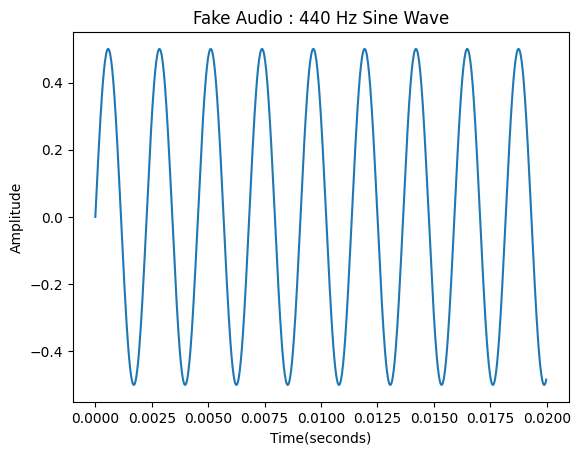

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#create fake audio: a 440 Hz sine wave

sample_rate = 44100
duration = 0.02
# 20 mlliseconds is enough to see the wave clearly
frequency = 440
# a 440 Hz wave repeats 440 times each second . if you plot a full second, the wave is so dense that it looks like a solid block
n_samples = int(sample_rate * duration)
# we use int() becuase sample_rate * duration can be a float, but the number of audio samples must be a whole number.
#np.arange() expects an integer stop value: using int() makes the results safe and predictable.

time = np.arange(n_samples)/sample_rate
audio = 0.5 * np.sin(2 * np.pi * frequency * time)

#show the sine wave
plt.plot(time,audio)
plt.title("Fake Audio : 440 Hz Sine Wave")
plt.xlabel("Time(seconds)")
plt.ylabel("Amplitude")
plt.show()

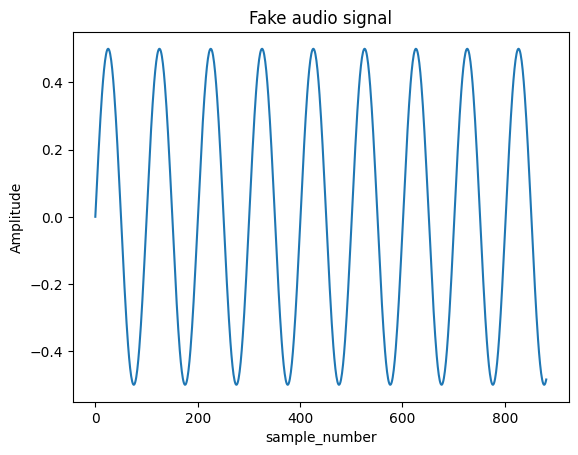

In [ ]:
plt.plot(audio)
plt.title("Fake audio signal")
plt.xlabel("sample_number")
plt.ylabel("Amplitude")
plt.show()

dtype: float64
shape: (882, 2)


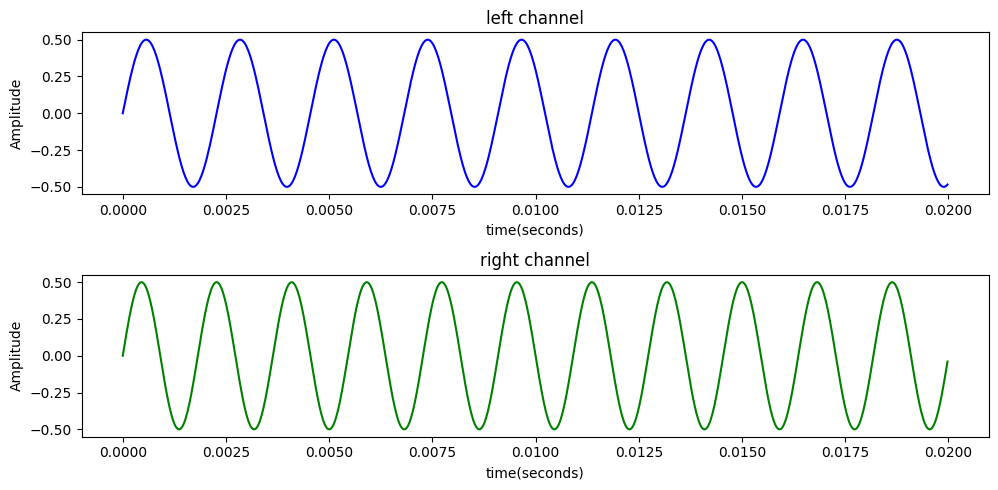

In [ ]:
# to plot the stereo audio , plot the left and right channel separetely. a stereo array commonly has shape (n_sample,2)
#column 0 is the left channel and column 1 is the right channel

import numpy as np
import matplotlib.pyplot as plt

sample_rate = 44100
duration = 0.02
n_samples = int(sample_rate * duration)

time = np.arange(n_samples)/sample_rate

#create two different sine wav for left and right channels
left = 0.5 * np.sin(2 * np.pi * 440 * time)
right = 0.5 * np.sin(2 * np.pi * 550 * time)

#put them in one stereo array
stereo_audio = np.stack([left, right], axis=1)

print("dtype:", stereo_audio.dtype)
print("shape:", stereo_audio.shape)

#plot both channels
plt.figure(figsize=(10,5))

plt.subplot(2,1,1)
# creates the top plot
plt.plot(time, stereo_audio[:, 0], color = "blue")
#stereo_audio[:,1]:selects all samples in the first column : the left channel
plt.title("left channel")
plt.xlabel("time(seconds)")
plt.ylabel("Amplitude")

plt.subplot(2, 1, 2)
#creates the bottom plot
plt.plot(time, stereo_audio[:,1], color = "green")
#stereo_audio[:,1]:selects all samples in the second column : the right channel
plt.title("right channel")
plt.xlabel("time(seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [1]:
import datasets
from datasets import load_dataset

dataset = load_dataset("hf-internal-testing/librispeech_asr_dummy", "clean", split="validation")

sample = dataset[0]

README.md:   0%|          | 0.00/520 [00:00<?, ?B/s]

clean/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 9.19MB            

clean/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/73 [00:00<?, ? examples/s]

In [2]:
audio = sample["audio"]
print(audio)
#it is a decoder object that can decode the audio file

In [3]:
samples = audio.get_all_samples()
# data: the actual audio samples as a PyTorch tensor
# sample_rate : the sampling rate
# duration_seconds : audio length in seconds

In [13]:
audio_array = samples.data[0]
#take one channel -> mono-audio
#offical whisper documentation explicity says feature extractor expects mono-channel audio, not stereo
sample_rate = samples.sample_rate

print("audio_array:",audio_array)
print("sample_rate:",sample_rate)

audio_array: tensor([0.0024, 0.0021, 0.0020,  ..., 0.0004, 0.0006, 0.0010])
sample_rate: 16000


In [6]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration

In [10]:
processor = WhisperProcessor.from_pretrained("openai/whisper-tiny.en")
model = WhisperForConditionalGeneration.from_pretrained("openai/whisper-tiny.en")

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

In [14]:
input_features = processor(
    #processor is like a preparation assistant for Whisper.it does two jobs:
    #1.turns raw audio into input_features
    #later,turns whisper's token IDs back into text
    audio_array,
    #a long list of numbers , where each number is the loudness/amplitude of the sound at one tiny moment in time
    sampling_rate = sample_rate,
    # this tells the processor how fast the audio was recorded
    return_tensors="pt",
#what kind of array-like object do you want the processor to give back?
# the whisper feature extractor accepts "pt" for pytorch tensors, "np" for numpy arrays, and "tf" for tensorflow tensors.
#Whisper wants a 1-dimensional waveform
).input_features

#translator between raw sound and Whisper. takes your audio array-> checks its sampling rate ->
# converts it into a special image-like representation of sound -> returns it as a pytorch tensor
predicted_ids=model.generate(input_features)

prediction = processor.batch_decode(
    predicted_ids,
    skip_special_tokens=True
)[0]

print(prediction)
# error: your audio is probably stereo or has shape(channels,samples), but whisper needs mono audio:one value per time step.

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


 Mr. Quilter is the apostle of the middle classes, and we are glad to welcome his gospel.


samples. data        often (channels, samples)
samples.data[0]      one-channel: (samples,)
use samples.data[0] -> when calling a processor